# Pilot: do DTW-similar trajectory pairs have higher shingle similarity?

For n = 500 trajectories, compare the exact Jaccard similarity of shingle sets
(cells → collapse repeats → k-shingles) with exact DTW from the ground truth.
No MinHash yet: this is the best case MinHash-LSH can approximate.


### Imports and project root:

In [8]:
import os, sys, time
import numpy as np
import pandas as pd
import h3
from scipy import sparse
from scipy.stats import spearmanr, mannwhitneyu
import matplotlib.pyplot as plt

def find_project_root(target_folder="masteroppgave"):
    current = os.getcwd()
    while True:
        if os.path.basename(current) == target_folder:
            return current
        parent = os.path.dirname(current)
        if parent == current:
            raise RuntimeError(f"Could not find '{target_folder}' above {os.getcwd()}")
        current = parent

project_root = find_project_root()
if project_root not in sys.path:
    sys.path.append(project_root)

from utils.helpers.file_handler import load_trajectories_from_meta_file
print("Project root:", project_root)


Project root: c:\Users\tonje\Documents\masteroppgave


### Settings

In [ ]:
CITY = "porto"     # "porto" or "rome"
SIZE = 500
THETA = 0.1        # DTW threshold for "truly similar", as in the thesis
K_VALUES = [1, 2, 3]
DISCRETISATIONS = [
    ("h3", 7), ("h3", 8), ("h3", 9),                       # H3 resolution
    ("square", 1.0), ("square", 0.5), ("square", 0.25),    # square cell side in km
]

OUTPUT_DIR = os.path.join(project_root, "results_pilot")
os.makedirs(OUTPUT_DIR, exist_ok=True)


### Load trajectories and ground truth:

In [10]:
data_folder = os.path.join(project_root, "dataset", CITY, "output") + os.sep
gt_file = os.path.join(project_root, "results_true", "similarity_values", CITY, "dtw", f"{CITY}-dtw-{SIZE}.csv")

trajectories = load_trajectories_from_meta_file(SIZE, data_folder)   # {name: [[lat, lon], ...]}
gt = pd.read_csv(gt_file, index_col=0)
names = list(gt.index)
assert set(names) == set(trajectories), f"Ground truth and META-{SIZE} contain different trajectories"
assert list(gt.columns) == names

M = gt.apply(pd.to_numeric, errors="coerce").to_numpy(dtype=float)
M = np.nan_to_num(M, nan=0.0)
assert np.allclose(np.triu(M, 1), 0), "Expected a lower-triangular matrix"
D = M + M.T                                  # make it symmetric

n = len(names)
iu, ju = np.triu_indices(n, k=1)             # every pair exactly once
dtw = D[iu, ju]
similar = dtw < THETA

print(f"{CITY}: {n} trajectories, {len(dtw)} pairs, {similar.sum()} similar pairs (DTW < {THETA})")
print("Median points per trajectory:", np.median([len(trajectories[t]) for t in names]))


rome: 500 trajectories, 124750 pairs, 46 similar pairs (DTW < 0.1)
Median points per trajectory: 79.5


### Cells, shingles and Jaccard

In [11]:
# Square cells: project lat/lon to km with a local flat-earth approximation (accurate enough within a city)
all_points = np.array([p for t in names for p in trajectories[t]])
LAT0 = all_points[:, 0].mean()
KM_PER_DEG_LAT = 110.574
KM_PER_DEG_LON = 111.320 * np.cos(np.radians(LAT0))

def to_cells(traj, method, param):
    """Map every GPS point to a cell id."""
    if method == "h3":
        return [h3.latlng_to_cell(lat, lon, param) for lat, lon in traj]
    if method == "square":
        return [(int(np.floor(lon * KM_PER_DEG_LON / param)),
                 int(np.floor(lat * KM_PER_DEG_LAT / param))) for lat, lon in traj]
    raise ValueError(method)

def collapse(cells):
    """Remove consecutive repeats: A A B B B A -> A B A."""
    out = [cells[0]]
    for c in cells[1:]:
        if c != out[-1]:
            out.append(c)
    return out

def shingles(seq, k):
    """Set of ordered k-grams. Sequences shorter than k become one shingle."""
    if len(seq) < k:
        return {tuple(seq)}
    return {tuple(seq[i:i + k]) for i in range(len(seq) - k + 1)}

def pairwise_jaccard(sets):
    """Exact Jaccard for all pairs, via a sparse trajectory x shingle matrix."""
    vocab, rows, cols = {}, [], []
    for r, s in enumerate(sets):
        for sh in s:
            cols.append(vocab.setdefault(sh, len(vocab)))
            rows.append(r)
    X = sparse.csr_matrix((np.ones(len(rows)), (rows, cols)), shape=(len(sets), len(vocab)))
    inter = (X @ X.T).toarray()                       # |A ∩ B|
    size = np.asarray(X.sum(axis=1)).ravel()          # |A|
    union = size[:, None] + size[None, :] - inter     # |A ∪ B|
    J = np.divide(inter, union, out=np.zeros_like(inter), where=union > 0)
    return J, len(vocab)


### Running all configurations:

In [12]:
rows, J_store = [], {}

for method, param in DISCRETISATIONS:
    t0 = time.perf_counter()
    seqs = [collapse(to_cells(trajectories[t], method, param)) for t in names]
    t_cells = time.perf_counter() - t0

    for k in K_VALUES:
        t1 = time.perf_counter()
        J, vocab = pairwise_jaccard([shingles(s, k) for s in seqs])
        j = J[iu, ju]
        t_jac = time.perf_counter() - t1
        J_store[(method, param, k)] = j

        js, jn = j[similar], j[~similar]
        thr_all = js.min()                 # highest threshold that keeps every similar pair
        thr_95 = np.quantile(js, 0.05)     # threshold that keeps 95 % of similar pairs
        rows.append({
            "Method": method, "Param": param, "k": k,
            "Cells/traj (median)": np.median([len(s) for s in seqs]),
            "Vocab": vocab,
            "J similar (median)": np.median(js),
            "J other (median)": np.median(jn),
            "Spearman(J, DTW)": spearmanr(j, dtw).statistic,
            "AUC": mannwhitneyu(js, jn).statistic / (len(js) * len(jn)),
            "Similar with J=0": int((js == 0).sum()),
            "Thr recall=1": thr_all,
            "Cand. ratio recall=1": (j >= thr_all).mean(),
            "Thr recall=0.95": thr_95,
            "Cand. ratio recall=0.95": (j >= thr_95).mean(),
            "Time cells (s)": t_cells,
            "Time Jaccard (s)": t_jac,
        })

results = pd.DataFrame(rows)
results.to_csv(os.path.join(OUTPUT_DIR, f"shingle_pilot_{CITY}_{SIZE}.csv"), index=False)
pd.set_option("display.width", 250)
print(results.round(4).to_string(index=False))


Method  Param  k  Cells/traj (median)  Vocab  J similar (median)  J other (median)  Spearman(J, DTW)    AUC  Similar with J=0  Thr recall=1  Cand. ratio recall=1  Thr recall=0.95  Cand. ratio recall=0.95  Time cells (s)  Time Jaccard (s)
    h3   7.00  1                  2.0     14              1.0000            0.2500           -0.4849 0.9593                 0        0.5000                0.2373           0.6667                   0.1452          0.0391            0.0055
    h3   7.00  2                  2.0     50              1.0000            0.0000           -0.3022 0.9629                 2        0.0000                1.0000           0.3750                   0.0469          0.0391            0.0033
    h3   7.00  3                  2.0    153              1.0000            0.0000           -0.1797 0.8921                 9        0.0000                1.0000           0.0000                   1.0000          0.0391            0.0027
    h3   8.00  1                  6.0     64    

### Plotting the best configuration:

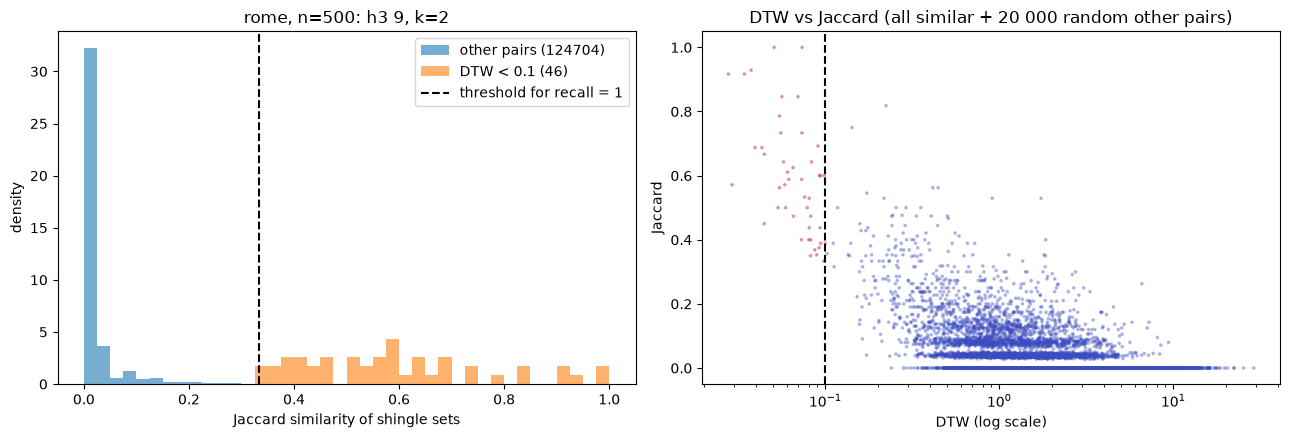

Plotted: h3 9, k=2


In [13]:
best = results.loc[results["Cand. ratio recall=1"].idxmin()]
key = (best["Method"], best["Param"], int(best["k"]))
j = J_store[key]
label = f"{key[0]} {key[1]:g}, k={key[2]}"

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

bins = np.linspace(0, 1, 41)
axes[0].hist(j[~similar], bins=bins, density=True, alpha=0.6, label=f"other pairs ({(~similar).sum()})")
axes[0].hist(j[similar], bins=bins, density=True, alpha=0.6, label=f"DTW < {THETA} ({similar.sum()})")
axes[0].axvline(best["Thr recall=1"], color="k", ls="--", label="threshold for recall = 1")
axes[0].set_xlabel("Jaccard similarity of shingle sets")
axes[0].set_ylabel("density")
axes[0].set_title(f"{CITY}, n={SIZE}: {label}")
axes[0].legend()

rng = np.random.default_rng(0)
idx = np.concatenate([np.flatnonzero(similar),
                      rng.choice(np.flatnonzero(~similar), 20000, replace=False)])
axes[1].scatter(dtw[idx], j[idx], s=3, alpha=0.3, c=similar[idx], cmap="coolwarm")
axes[1].set_xscale("log")
axes[1].axvline(THETA, color="k", ls="--")
axes[1].set_xlabel("DTW (log scale)")
axes[1].set_ylabel("Jaccard")
axes[1].set_title("DTW vs Jaccard (all similar + 20 000 random other pairs)")

fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, f"shingle_pilot_{CITY}_{SIZE}.png"), dpi=150)
plt.show()
print("Plotted:", label)


In [14]:
cols = ["Method", "Param", "k", "Cells/traj (median)", "AUC", "Spearman(J, DTW)", "Similar with J=0",
        "Thr recall=1", "Cand. ratio recall=1", "Thr recall=0.95", "Cand. ratio recall=0.95",
        "Time cells (s)", "Time Jaccard (s)"]
print(f"CITY={CITY}, SIZE={SIZE}, THETA={THETA}, similar pairs={similar.sum()}")
print(results[cols].round(4).to_csv(index=False))
print("Plotted:", label)


CITY=rome, SIZE=500, THETA=0.1, similar pairs=46
Method,Param,k,Cells/traj (median),AUC,"Spearman(J, DTW)",Similar with J=0,Thr recall=1,Cand. ratio recall=1,Thr recall=0.95,Cand. ratio recall=0.95,Time cells (s),Time Jaccard (s)
h3,7.0,1,2.0,0.9593,-0.4849,0,0.5,0.2373,0.6667,0.1452,0.0391,0.0055
h3,7.0,2,2.0,0.9629,-0.3022,2,0.0,1.0,0.375,0.0469,0.0391,0.0033
h3,7.0,3,2.0,0.8921,-0.1797,9,0.0,1.0,0.0,1.0,0.0391,0.0027
h3,8.0,1,6.0,0.9957,-0.5739,0,0.5,0.0427,0.5786,0.017,0.0293,0.0048
h3,8.0,2,6.0,0.9974,-0.3922,0,0.2857,0.0216,0.3333,0.0159,0.0293,0.0036
h3,8.0,3,6.0,0.9857,-0.2451,1,0.0,1.0,0.175,0.0167,0.0293,0.0033
h3,9.0,1,15.0,0.9989,-0.5565,0,0.4706,0.0077,0.5,0.0063,0.0271,0.0066
h3,9.0,2,15.0,0.9991,-0.4315,0,0.3333,0.0053,0.3568,0.0037,0.0271,0.006
h3,9.0,3,15.0,0.9987,-0.3291,0,0.2,0.0099,0.2819,0.004,0.0271,0.0056
square,1.0,1,6.0,0.9869,-0.5705,0,0.4286,0.0919,0.5,0.0617,0.0201,0.0047
square,1.0,2,6.0,0.9821,-0.407,0,0.125,0.1315,0.1429,0.1046,0.0201,0.004
square,1.0,3,6